# 02 — Monthly indicators

Collects monthly indicators for the nowcast from Jan 2014 to the latest month available, and aggregates them to calendar quarters.

**Rules**
- Every value is parsed from a downloaded file, and its URL is recorded. Nothing is typed in by hand.
- Gaps stay blank. They appear as blank rows in the monthly file and in the data gaps cell at the end.
- Each base year is a separate series (`..._base2011`), so nothing is spliced and no YoY crosses a base change.
- `vintage` is `first` for the earliest published value found and `latest` for the current official series.

**Files written**
- `indicators_monthly.csv`: the requested columns, in long format.
- `indicators_quarterly.csv`: quarterly values and YoY, with a `complete` flag.
- `indicators_coverage.csv`: the coverage and lag table.
- `indicators_provenance.csv`: how each release date was obtained.

**Fetching:** files are downloaded with curl, because Python's bundled certificates reject two of the government hosts. Certificate checks stay on.


In [1]:
import calendar, html, json, re, subprocess, urllib.parse as up, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pdfplumber
from IPython.display import display

warnings.filterwarnings("ignore", message=".*xlrd.*")
RAW = Path("../data/raw/indicators"); RAW.mkdir(parents=True, exist_ok=True)
PROCESSED = Path("../data/processed"); REPORTS = Path("../reports")
START, END = pd.Period("2014-01", "M"), pd.Period("2026-10", "M")
UA = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120 Safari/537.36"
MONTHS = {m.lower(): i for i, m in enumerate(calendar.month_name) if m}
MON3 = {m.lower(): i for i, m in enumerate(calendar.month_abbr) if m}
MONTH_RE = "|".join(calendar.month_name[1:])

def fetch(url, path, data=None, timeout=90):
    # curl, because Python's bundled certificates reject eaindustry.nic.in and api.mospi.gov.in;
    # curl uses the Windows store with verification on. Results are cached, failures are not.
    path = Path(path)
    if path.exists() and path.stat().st_size > 0:
        return True
    cmd = ["curl", "-sL", "-A", UA, "--max-time", str(timeout), "-o", str(path), "-w", "%{http_code}"]
    if data:
        cmd += ["--data-binary", "@-", "-H", "Content-Type: application/x-www-form-urlencoded"]
    out = subprocess.run(cmd + [url], capture_output=True, input=data.encode() if data else None)
    if out.stdout.decode().strip() != "200":
        path.unlink(missing_ok=True)
        return False
    return True

def fetch_all(jobs, workers=8):
    # jobs: (url, path) pairs
    with ThreadPoolExecutor(workers) as pool:
        return list(pool.map(lambda j: fetch(*j), jobs))

def is_pdf(path):
    path = Path(path)
    return path.exists() and path.read_bytes()[:4] == b"%PDF"

def pdf_pages(path):
    try:
        with pdfplumber.open(path) as pdf:
            return [re.sub(r"[ \t]+", " ", page.extract_text() or "") for page in pdf.pages], pdf.metadata or {}
    except Exception as err:
        # A truncated download: drop it from the cache so a rerun fetches it again, and count it as a failure.
        print("unreadable, removed from cache:", Path(path).name, type(err).__name__)
        Path(path).unlink(missing_ok=True)
        return [], {}

def squash(text):
    return re.sub(r"\s+", " ", text)

def meta_date(meta):
    m = re.match(r"D:(\d{4})(\d{2})(\d{2})", str(meta.get("CreationDate", "")))
    return pd.Timestamp(f"{m[1]}-{m[2]}-{m[3]}") if m else pd.NaT

def cdx(url, pattern=None, limit=4000):
    # Wayback's index, cached so that reruns use the same file list.
    name = RAW / ("cdx_" + re.sub(r"\W+", "_", url) + ".txt")
    fetch(f"https://web.archive.org/cdx/search/cdx?url={up.quote(url, safe='/*:')}&output=txt&fl=timestamp,original"
          f"&collapse=urlkey&filter=statuscode:200&limit={limit}", name, timeout=170)
    lines = name.read_text("utf8", "ignore").splitlines() if name.exists() else []
    rows = [l.split(" ", 1) for l in lines if " " in l]
    return [(t, u) for t, u in rows if not pattern or re.search(pattern, u, re.I)]

records, method_notes = [], {}

def add(indicator, ref_month, value, unit, release_date, vintage, source_url, date_method=""):
    records.append(dict(indicator=indicator, ref_month=str(ref_month), value=value, unit=unit,
                        release_date=release_date, vintage=vintage, source_url=source_url, date_method=date_method))

## 1. IIP

In [2]:
IIP_API = "https://api.mospi.gov.in/api/iip/getIIPMonthly"
for base, tag in (("2011-12", "2011"), ("2022-23", "2022")):
    url = f"{IIP_API}?base_year={base}&type=General&limit=200"
    path = RAW / f"iip_api_{tag}.json"
    if fetch(url, path):
        for row in json.loads(path.read_text("utf8"))["data"]:
            if row["category"] == "General":
                ref = pd.Period(f"{row['year']}-{MONTHS[row['month'].lower()]:02d}", "M")
                if ref >= START:
                    add(f"iip_general_base{tag}", ref, float(row["index"]), "index", pd.NaT, "latest", url)

iip_files = {u.split("?")[0]: t for host in ("mospi.gov.in", "mospi.nic.in")
             for t, u in cdx(f"{host}/sites/default/files/press_release/*", r"iip.*\.pdf$")
             if not re.search(r"/(h_|hindi)|hindi|corrigendum", u, re.I)}
def iip_job(item):
    url, stamp = item
    name = re.sub(r"\W+", "_", url.split("/")[-1])[:90] + ".pdf"
    path = RAW / "iip" / name
    path.parent.mkdir(exist_ok=True)
    live = url.replace("http://", "https://").replace(":80/", "/")
    return live if fetch(live, path) else (f"https://web.archive.org/web/{stamp}id_/{url}" if fetch(f"https://web.archive.org/web/{stamp}id_/{url}", path) else None), path
with ThreadPoolExecutor(8) as pool:
    iip_got = list(pool.map(iip_job, iip_files.items()))

IIP_PAT = [
    rf"(?:Index of Industrial Production|IIP)[^.]{{0,140}}?(?:for|in|of)(?: the month of)?\s*({MONTH_RE})[ ,']*(\d{{4}})[^.]{{0,90}}?(?:stands? at|stood at|at)\s*(\d{{2,3}}\.\d)",
    rf"General (?:Index|index)[^.]{{0,80}}?(?:for|in)(?: the month of)?\s*({MONTH_RE})[ ,']*(\d{{4}})[^.]{{0,90}}?(?:stands? at|stood at|at)\s*(\d{{2,3}}\.\d)",
    rf"({MONTH_RE})[ ,']*(\d{{4}})[^.]{{0,60}}?General[^.]{{0,60}}?(?:stands? at|stood at|is)\s*(\d{{2,3}}\.\d)",
]
iip_rows, iip_fail = [], []
for url, path in iip_got:
    if url is None or not is_pdf(path):
        continue
    pages, meta = pdf_pages(path)
    text = squash(" ".join(pages[:3]))
    hit = next((m for p in IIP_PAT for m in [re.search(p, text)] if m), None)
    if hit:
        ref_month, ref_year, value = hit[1], hit[2], hit[3]
    else:
        # From 2020 the month and the index sit in separate clauses.
        level = re.search(r"Quick Estimates? of (?:Index of Industrial Production \(IIP\)|IIP)[^.]{0,40}?stands? at\s*(\d{2,3}\.\d)", text)
        month = re.search(rf"[Ff]or the month of\s*({MONTH_RE})[ ,']*(\d{{4}})", text)
        if not level or not month:
            iip_fail.append(path.name); continue
        ref_month, ref_year, value = month[1], month[2], level[1]
    base = re.search(r"(?:[Bb]ase|BASE)\s*(?:[Yy]ear)?[^0-9]{0,15}(2004-05|2011-12|2022-23)", " ".join(pages)) or re.search(r"(2022-23|2011-12|2004-05)\s*=\s*100", " ".join(pages))
    ref = pd.Period(f"{ref_year}-{MONTHS[ref_month.lower()]:02d}", "M")
    base_inferred = not base
    if base_inferred and not pd.Period("2017-04", "M") <= ref <= pd.Period("2025-09", "M"):
        iip_fail.append(path.name + " (no base)"); continue
    released = (re.search(rf"(\d{{1,2}})\s*(?:st|nd|rd|th)?\s*({MONTH_RE}),?\s*(\d{{4}})", text[:600])
                or re.search(rf"()({MONTH_RE})\s*(\d{{1,2}})(?:st|nd|rd|th)?,\s*(\d{{4}})", text[:600]))
    if released and released[1] == "":
        date = pd.to_datetime(f"{released[3]} {released[2]} {released[4]}", format="%d %B %Y", errors="coerce")
    else:
        date = pd.to_datetime(f"{released[1]} {released[2]} {released[3]}", format="%d %B %Y", errors="coerce") if released else pd.NaT
    iip_rows.append(dict(ref=ref, value=float(value), base=base[1] if base else "2011-12", url=url, date=date if pd.notna(date) else meta_date(meta),
                         method=("press note" if pd.notna(date) else "pdf_created") + ("; base inferred" if base_inferred else "")))
iip_first = pd.DataFrame(iip_rows)
if len(iip_first):
    iip_first = iip_first[iip_first["ref"] >= START].sort_values(["ref", "date"]).drop_duplicates("ref")
    for r in iip_first.itertuples():
        add(f"iip_general_base{r.base[:4]}", r.ref, r.value, "index", r.date, "first", r.url, r.method)
print(f"IIP files {len(iip_got)}, parsed {len(iip_rows)}, failed {len(iip_fail)}: {iip_fail[:25]}")
print(iip_first.groupby("base")["ref"].agg(["min", "max", "count"]).to_string() if len(iip_first) else "none")

unreadable, removed from cache: IIP_20Nov_2720_20Press_20Release_Approved_20_pdf.pdf PdfminerException


IIP files 215, parsed 206, failed 9: ['IIP_20Dec_23_20Press_20Release_pdf.pdf', 'IIP_20Jan_2724_20Press_20Release_pdf.pdf', 'IIP_20Nov_2723_20Press_20Release_pdf.pdf', 'IIP_20press_20release_20October18_pdf.pdf', 'iip_PR_12may17_pdf.pdf', 'NEW_timeline_IIP_press_release_17_04_25_pdf.pdf', 'IIP_20Nov_2720_20Press_20Release_Approved_20_pdf.pdf', 'IIP_20press_20release_20October18_pdf.pdf', 'iip_PR_12may17_pdf.pdf']
             min      max  count
base                            
2004-05  2014-02  2017-02     36
2011-12  2017-04  2025-09     94


## 2. Eight core industries

In [3]:
EA = "https://eaindustry.nic.in/"
core_ok = {}
for fname, tag, skip in (("Core Industries 2004-05.xlsx", "2004", 0), ("Core_Industries_2011_12_20260720.xlsx", "2011", 0), ("Core_Industries_2022_23_20261021.xlsx", "2022", 0)):
    url = EA + "eight_core_infra/" + up.quote(fname)
    path = RAW / f"core_{tag}.xlsx"
    if not fetch(url, path):
        continue
    df = pd.read_excel(path, sheet_name="Index", header=None)
    head = next(i for i in range(6) if str(df.iat[i, 0]).strip().startswith("Months"))
    cols = [str(c).lower() for c in df.iloc[head]]
    overall = next(i for i, c in enumerate(cols) if "overall" in c)
    electric = next(i for i, c in enumerate(cols) if "electric" in c)
    for row in df.iloc[head + 1:].itertuples(index=False):
        raw_month = row[0]
        if isinstance(raw_month, str) and not re.fullmatch(r"[A-Za-z]{3}-\d{2}", raw_month.strip()):
            continue
        ref = pd.Period(pd.to_datetime(raw_month, format="%b-%y") if isinstance(raw_month, str) else raw_month, "M")
        if START <= ref and pd.notna(row[overall]):
            add(f"core8_overall_base{tag}", ref, round(float(row[overall]), 2), "index", pd.NaT, "latest", url)
            add(f"electricity_core_index_base{tag}", ref, round(float(row[electric]), 2), "index", pd.NaT, "latest", url)

def core_job(period):
    url = f"{EA}archive_data/ici_press_release/IPR_{period.year}_{period.month:02d}.pdf"
    path = RAW / "core" / f"IPR_{period.year}_{period.month:02d}.pdf"
    path.parent.mkdir(exist_ok=True)
    return period, url, path, fetch(url, path)
with ThreadPoolExecutor(8) as pool:
    core_got = list(pool.map(core_job, pd.period_range(START, "2026-08", freq="M")))
late = RAW / "core" / "IPR_2026_09.pdf"
if fetch(EA + "eight_core_infra/Press_Release_ICI_20261021.pdf", late):
    core_got.append((pd.Period("2026-09", "M"), EA + "eight_core_infra/Press_Release_ICI_20261021.pdf", late, True))

core_fail, core_dates, core_quoted = [], {}, {}
for period, url, path, ok in core_got:
    if not ok or not is_pdf(path):
        core_fail.append(str(period)); continue
    pages, meta = pdf_pages(path)
    text = squash(" ".join(pages))
    month = calendar.month_name[period.month]
    hits = [re.search(rf"(?:stands?|stood|was|is)\s*(?:at)?\s*(\d{{2,3}}\.\d)\s*(?:\(?Provisional\)?)?\s*(?:in|for|during)\s*(?:the month of\s*)?{month}", text, re.I),
            re.search(rf"[Ii]ndex[^.]{{0,160}}?{month}[ ,]*(?:{period.year})?[^.]{{0,70}}?(?:stands?|stood|was|is|at)\s*(?:at)?\s*(\d{{2,3}}\.\d)", text),
            re.search(rf"Overall Index[^0-9]{{0,40}}(?:\d[\d.]* ){{0,14}}?(\d{{2,3}}\.\d)\*?\s*$", text)]
    table = next((re.findall(r"-?\d+\.\d+", line) for page in pages for line in page.split("\n")
                  if re.match(r"(Overall|Combined|ICI|General)\b.*Index|Overall Index|Overall", line.strip()) and len(re.findall(r"\d+\.\d+", line)) >= 6), None)
    value = next((float(h[1]) for h in hits[:2] if h), None)
    if value is None:
        # Annex II: the first row for the month is the index table, and its last column is the overall index.
        label = f"{period.strftime('%b')}-{str(period.year)[-2:]}"
        row = next((re.findall(r"-?\d+\.\d+", line) for page in pages for line in page.split("\n")
                    if re.match(rf"{label}\s*(?:\*|\(P\))?\s+\d", line.strip())), None)
        if row and len(row) >= 8:
            value = float(row[-1])
    base = re.search(r"base[^0-9]{0,20}(2004-05|2011-12|2022-23)", text, re.I)
    embargo = re.search(rf"till [^.]{{0,40}}?(\d{{1,2}})\s*(?:st|nd|rd|th)\s*({MONTH_RE}),?\s*(\d{{4}})", text[:400])
    date = pd.to_datetime(f"{embargo[1]} {embargo[2]} {embargo[3]}", format="%d %B %Y") if embargo else meta_date(meta)
    core_dates[period] = (date, url, "embargo line" if embargo else "pdf_created")
    quoted = re.search(rf"final index for the month of ({MONTH_RE}) (\d{{4}}) has been revised from (\d{{2,3}}\.\d)", text)
    if quoted:
        core_quoted[pd.Period(f"{quoted[2]}-{MONTHS[quoted[1].lower()]:02d}", "M")] = (float(quoted[3]), url, base[1] if base else None)
    if value is None or base is None:
        core_fail.append(f"{period}*"); continue
    add(f"core8_overall_base{base[1][:4]}", period, value, "index", date, "first", url, "embargo line" if embargo else "pdf_created")
# Later notes quote the provisional index of the month before, which is that month's first print.
already = {r["ref_month"] for r in records if r["indicator"].startswith("core8") and r["vintage"] == "first"}
for period, (value, url, base) in core_quoted.items():
    if str(period) not in already and base and period in core_dates:
        add(f"core8_overall_base{base[:4]}", period, value, "index", core_dates[period][0], "first", url, core_dates[period][2] + "; value quoted in next note")
        core_fail = [f for f in core_fail if f != f"{period}*"]
print("core releases", len(core_got), "still failed", core_fail)

core releases 153 still failed ['2014-03*', '2015-07*', '2016-05*', '2016-09*', '2016-12*', '2017-01*', '2017-02*', '2017-03*', '2017-04*', '2024-12*', '2026-09*']


## 3. Petroleum (PPAC)

In [4]:
ppac_files = {}
for fy in [f"{y}-{y + 1}" for y in range(2014, 2027)]:
    path = RAW / f"ppac_{fy}.json"
    url = "https://ppac.gov.in/AjaxController/getConsumptionPetroleumProductsData"
    if not fetch(url, path, data=f"financialYear={fy}&reportBy=1&pageId=43"):
        continue
    rows = json.loads(path.read_text("utf8"))["result"]
    for row in (rows.values() if isinstance(rows, dict) else rows):
        title = re.sub(r"<[^>]+>", "", str(row.get("title", ""))).strip().upper()
        name = {"MS": "petrol_ms_consumption", "PETROL": "petrol_ms_consumption", "MS (PETROL)": "petrol_ms_consumption",
                "HSD": "diesel_hsd_consumption", "DIESEL": "diesel_hsd_consumption", "HSDO": "diesel_hsd_consumption"}.get(title)
        if not name:
            continue
        start = int(fy[:4])
        for i, month in enumerate(("april", "may", "june", "july", "august", "september", "october", "november", "december", "january", "february", "march")):
            if row.get(month) not in ("", None):
                ref = pd.Period(f"{start + (i >= 9)}-{i + 4 if i < 9 else i - 8:02d}", "M")
                add(name, ref, float(str(row[month]).replace(",", "")), "000 tonnes", pd.NaT, "latest", row["file_name"].replace(" ", "%20"))
print("ppac rows", sum(r["indicator"].endswith("consumption") for r in records))

ppac_old = cdx("ppac.gov.in/*", r"(PT_?consumption|consumption).*\.xls")
print("ppac archived spreadsheets:", len(ppac_old), [u.split("/")[-1] for _, u in ppac_old][:12])

ppac rows 156
ppac archived spreadsheets: 2 ['1666084300_PT_sales_statewise.xls', '1679031392_PT_Consumption_H.xls']


## 4. Electricity (CEA via National Power Portal)

In [5]:
def npp_job(args):
    period, kind = args
    mon = period.strftime("%b").upper()
    url = f"https://npp.gov.in/public-reports/cea/monthly/generation/18_col_{kind}/{period.year}/{mon}/18_col_{kind}-1_{period.year}-{mon}.xls"
    path = RAW / "npp" / f"{kind}_{period}.xls"
    path.parent.mkdir(exist_ok=True)
    return period, kind, url, path, fetch(url, path)
with ThreadPoolExecutor(8) as pool:
    npp_got = list(pool.map(npp_job, [(p, k) for p in pd.period_range(START, "2026-09", freq="M") for k in ("act", "ten")]))
npp_rows = []
for period, kind, url, path, ok in npp_got:
    if not ok:
        continue
    try:
        df = pd.read_excel(path, header=None)
    except Exception:
        continue
    head = next((i for i in range(len(df)) if "ACTUAL" in " ".join(map(str, df.iloc[i].values))), None)
    col = next(j for j, v in enumerate(df.iloc[head].values) if str(v).strip().startswith("ACTUAL")) if head is not None else None
    total = next((row for row in df.values if re.fullmatch(r"(grand )?total|all india", str(row[0]).strip(), re.I)), None) if col is not None else None
    if total is None:
        total = next((row for row in df.values if any(re.fullmatch(r"(grand )?total|all india|total.*", str(v).strip(), re.I) for v in row[:3])), None)
    if total is not None and pd.notna(total[col]):
        npp_rows.append((period, kind, float(total[col]), url))
for period, kind, value, url in npp_rows:
    add("electricity_generation_cea", period, value, "GWh", pd.NaT, "first" if kind == "ten" else "latest", url)
print("npp files", sum(j[4] for j in npp_got), "rows", len(npp_rows), pd.Series([k for _, k, _, _ in npp_rows]).value_counts().to_dict())

npp files 174 rows 174 {'ten': 87, 'act': 87}


## 5. PIB release index

In [6]:
PIB = "https://www.pib.gov.in/allRel.aspx?reg=3&lang=1"
fetch(PIB, RAW / "pib_home.html")
home = (RAW / "pib_home.html").read_text("utf8", "ignore")
hidden = {m[0]: html.unescape(m[1]) for m in re.findall(r'<input type="hidden" name="([^"]+)"[^>]*value="([^"]*)"', home)}
MINISTRIES = {"railways": "23", "commerce": "16", "finance": "15"}
def pib_month(args):
    key, period = args
    form = dict(hidden); prefix = "ctl00$ContentPlaceHolder1$ddl"
    form.update({prefix + "Ministry": MINISTRIES[key], prefix + "day": "0", prefix + "Month": str(period.month), prefix + "Year": str(period.year)})
    path = RAW / "pib" / f"list_{key}_{period}.html"
    path.parent.mkdir(exist_ok=True)
    fetch(PIB, path, data=up.urlencode(form))
    text = path.read_text("utf8", "ignore") if path.exists() else ""
    return [(key, m[0], squash(html.unescape(m[1])).strip()) for m in re.findall(r'PRID=(\d+)[^>]*>\s*(?:<[^>]+>\s*)*([^<]{10,240})', text)]
with ThreadPoolExecutor(6) as pool:
    pib_index = pd.DataFrame([x for rows in pool.map(pib_month, [(k, p) for k in MINISTRIES for p in pd.period_range("2017-01", "2026-10", freq="M")]) for x in rows],
                             columns=["ministry", "prid", "title"]).drop_duplicates("prid")
print(pib_index.groupby("ministry").size().to_dict())

def pib_release(prid):
    path = RAW / "pib" / f"pr_{prid}.html"
    url = f"https://www.pib.gov.in/PressReleasePage.aspx?PRID={prid}"
    if not fetch(url, path):
        return None
    raw = path.read_text("utf8", "ignore")
    body = squash(html.unescape(re.sub(r"<(script|style)[\s\S]*?</\1>|<[^>]+>", " ", raw)))
    posted = re.search(r"Posted On:?\s*(\d{1,2})\s*([A-Za-z]{3})\s*(\d{4})", body)
    date = pd.to_datetime(f"{posted[1]} {posted[2]} {posted[3]}", format="%d %b %Y", errors="coerce") if posted else pd.NaT
    return dict(prid=prid, url=url, body=body, date=date)

def releases(mask):
    with ThreadPoolExecutor(8) as pool:
        return [r for r in pool.map(pib_release, pib_index[mask]["prid"]) if r]

{'commerce': 4277, 'finance': 5969, 'railways': 2781}


## 6. Rail freight

In [7]:
rail = releases(pib_index["ministry"].eq("railways") & pib_index["title"].str.contains(r"freight|loading|\bMT\b", case=False))
rail_rows = {}
RAIL_PATS = [rf"(?:during|in|for) (?:the month of )?({MONTH_RE})[ ,']*(\d{{4}})[^.]{{0,70}}?(?:freight )?(?:loading|loaded)[^.]{{0,40}}?(\d{{2,3}}(?:\.\d+)?)\s*(?:million tonnes|MT|million tons)",
             rf"(?:loaded|loading of|loading was|carried)[^.]{{0,40}}?(\d{{2,3}}(?:\.\d+)?)\s*(?:million tonnes|MT|million tons)[^.]{{0,40}}?(?:during|in|for) (?:the month of )?({MONTH_RE})[ ,']*(\d{{4}})"]
for r in sorted(rail, key=lambda r: (pd.isna(r["date"]), r["date"])):
    for i, pat in enumerate(RAIL_PATS):
        for m in re.finditer(pat, r["body"], re.I):
            mon, yr, val = (m[1], m[2], m[3]) if i == 0 else (m[2], m[3], m[1])
            ref = pd.Period(f"{yr}-{MONTHS[mon.lower()]:02d}", "M")
            # The release must come after the month it reports; this also drops prior-year comparisons.
            if 60 <= float(val) <= 220 and pd.notna(r["date"]) and ref < r["date"].to_period("M") and (r["date"].to_period("M") - ref).n <= 2 and ref not in rail_rows:
                rail_rows[ref] = (float(val), r["date"], r["url"], m[0][:150])
for ref, (val, date, url, _) in sorted(rail_rows.items()):
    add("rail_freight_loading", ref, val, "million tonnes", date, "first", url, "PIB posted date")
print("rail releases", len(rail), "months", len(rail_rows), min(rail_rows, default=None), max(rail_rows, default=None))

rail releases 193 months 27 2020-08 2026-09


## 7. Domestic air passengers

In [8]:
aai = dict((u.split("/")[-1], (t, u)) for t, u in cdx("aai.aero/sites/default/files/traffic-news/*", r"annex-?_?\s?(1|I)[^0-9]*\.pdf$"))
aai_jobs = {}
for period in pd.period_range(START, "2026-09", freq="M"):
    stem = f"{period.strftime('%b')}2k{str(period.year)[-2:]}"
    for suffix in ("Annex1.pdf", "annex1.pdf", "Annex1_0.pdf", "Annex-1.pdf", "ANNEX1.pdf"):
        aai_jobs.setdefault(period, []).append(f"https://www.aai.aero/sites/default/files/traffic-news/{stem}{suffix}")
def aai_job(item):
    period, urls = item
    path = RAW / "aai" / f"{period}.pdf"
    path.parent.mkdir(exist_ok=True)
    for url in urls:
        if fetch(url, path, timeout=45) and is_pdf(path):
            return period, url, path
        path.unlink(missing_ok=True)
    return period, None, path
with ThreadPoolExecutor(8) as pool:
    aai_got = list(pool.map(aai_job, aai_jobs.items()))
aai_rows = 0
for period, url, path in aai_got:
    if url is None:
        continue
    pages, meta = pdf_pages(path)
    text = "\n".join(pages)
    section = text[text.find("PASSENGERS"):] if "PASSENGERS" in text else ""
    # The heading has the word alone on its line; "DOMESTIC AIRPORTS" rows also appear in the international block.
    dom = re.search(r"(?m)^(?:[^\n]*\s)?(?:DOMESTIC|Domestic)\s*$.*?(?:\bTotal|TOTAL)\s+([\d,]+)\s+([\d,]+)", section, re.S)
    if dom:
        add("air_domestic_passengers_aai", period, float(dom[1].replace(",", "")), "passengers (airport handled)", meta_date(meta), "first", url, "pdf_created")
        aai_rows += 1
print("aai pdfs", sum(u is not None for _, u, _ in aai_got), "parsed", aai_rows)

aai pdfs 120 parsed 120


## 8. Trade

In [9]:
trade = releases(pib_index["ministry"].eq("commerce") & pib_index["title"].str.contains(r"foreign trade|merchandise|overall exports|total exports|exports? .*imports?", case=False))
exports, imports = {}, {}
num = r"(?:US\s*\$|USD)\s*([\d.,]+)\s*(Billion|Million|billion|million)"
for r in sorted(trade, key=lambda r: (pd.isna(r["date"]), r["date"])):
    if pd.isna(r["date"]):
        continue
    body = r["body"]
    head = re.search(rf"({MONTH_RE})[ ,']*(\d{{4}})", body[body.find("Posted On"):][:1500] if "Posted On" in body else body)
    ref = r["date"].to_period("M") - 1
    month_name = calendar.month_name[ref.month]
    # Skip sub-aggregates: "non-petroleum and non-gems & jewellery exports in ..." has the same sentence shape.
    e = next((m for m in re.finditer(rf"[Ee]xports\s*(?:in|during|for)\s*(?:the month of\s*)?{month_name}[ ,']*{ref.year}\s*(?:were|was|stood at|are|is)\s*{num}", body)
              if not re.search(r"(?i)jewel|gems|GJ|petroleum|\boil|services|overall|total", body[max(0, m.start() - 60):m.start()])), None)
    i = re.search(rf"[Nn]on-?\s?(?:[Pp]etroleum|[Oo]il).{{0,40}}?[Gg](?:ems|J).{{0,70}}?[Ii]mports.{{0,90}}?{num}", body)
    def amount(m):
        g = [x for x in m.groups() if x]
        return float(g[0].replace(",", "").rstrip(".")) * (1 if g[1].lower() == "billion" else 0.001)
    if e and ref not in exports and 10 <= amount(e) <= 70:
        exports[ref] = (amount(e), r["date"], r["url"])
    if i and ref not in imports and 10 <= amount(i) <= 70:
        imports[ref] = (amount(i), r["date"], r["url"])
for name, store in (("merch_exports", exports), ("imports_non_oil_non_gems", imports)):
    for ref, (val, date, url) in sorted(store.items()):
        if START <= ref:
            add(name, ref, val, "USD billion", date, "first", url, "PIB posted date")
print("trade releases", len(trade), "exports", len(exports), "imports", len(imports))

trade releases 207 exports 95 imports 70


## 9. RBI Bulletin: non-food credit and UPI

In [10]:
RBI = "rbidocs.rbi.org.in/rdocs/Bulletin/DOCs/"
def bulletin_files(prefix):
    out = {}
    for stamp, url in cdx(RBI + prefix + "*", r"\.xlsx?$"):
        # Filenames carry DDMMYYYY, or DDMMYY in older bulletins, followed by a hex hash.
        m = re.search(prefix + r"(\d{2})(\d{2})(20(?:1[5-9]|2\d))", url) or re.search(prefix + r"(\d{2})(\d{2})(\d{2})", url)
        if m:
            year = m[3] if len(m[3]) == 4 else "20" + m[3]
            out[pd.Timestamp(f"{year}-{m[2]}-{m[1]}")] = (stamp, url)
    return out
def bulletin_fetch(prefix, stamp, url, date):
    path = RAW / "rbi_bulletin" / f"{prefix}{date:%Y%m%d}.xlsx"
    path.parent.mkdir(exist_ok=True)
    live = url.replace("http://", "https://").replace(":80/", "/")
    # RBI answers some requests with an HTML page and status 200, so check the bytes as well.
    for candidate in (live, f"https://web.archive.org/web/{stamp}id_/{url}"):
        if fetch(candidate, path):
            if path.read_bytes()[:2] in (b"PK", b"\xd0\xcf"):
                return path
            path.unlink(missing_ok=True)
    return None

def bulletin_month_columns(df):
    # Header rows carry "2023" spanning several month cells; read columns right-to-left as (year, month).
    columns = {}
    for i in range(min(9, len(df))):
        cells = [str(v).strip() for v in df.iloc[i].values]
        if not any(re.match(r"(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)", c) for c in cells):
            continue
        year = None
        years = [str(v) for v in df.iloc[i - 1].values] if i else []
        for j, c in enumerate(cells):
            if j < len(years) and re.fullmatch(r"(20\d\d)(\.0)?", years[j].strip()):
                year = int(float(years[j]))
            m = re.match(r"(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)", c)
            if m and year:
                columns[j] = pd.Period(f"{year}-{MON3[m[1].lower()]:02d}", "M")
    return columns

credit = {}
for date, (stamp, url) in sorted(bulletin_files("15T_").items()):
    path = bulletin_fetch("15T_", stamp, url, date)
    if path is None:
        continue
    try:
        df = pd.read_excel(path, header=None)
    except Exception:
        continue
    row = next((r for r in df.values if any(re.search(r"Non-?food Credit", str(v), re.I) for v in r[:3])), None)
    columns = bulletin_month_columns(df)
    if row is None or not columns:
        continue
    for j, ref in columns.items():
        # Older layouts put other figures in these columns; total non-food credit is above Rs 50 lakh crore throughout.
        if pd.notna(row[j]) and isinstance(row[j], (int, float, np.number)) and row[j] > 5_000_000:
            credit.setdefault(ref, []).append((date, float(row[j]), url))
def consistent(store):
    # Some bulletin layouts shift the year header, so a prior-year column gets read as this year.
    # A later bulletin disagreeing by more than 5% marks the earlier reading as unreliable.
    dropped = 0
    for ref, rows in store.items():
        rows.sort()
        keep = [r for r in rows if abs(r[1] / rows[-1][1] - 1) <= 0.05]
        dropped += len(rows) - len(keep)
        store[ref] = keep
    return dropped
print("credit readings dropped as inconsistent:", consistent(credit))
for ref, rows in sorted(credit.items()):
    rows.sort()
    add("non_food_credit", ref, rows[0][1], "INR crore (outstanding)", rows[0][0], "first", rows[0][2], "bulletin date in filename")
    add("non_food_credit", ref, rows[-1][1], "INR crore (outstanding)", rows[-1][0], "latest", rows[-1][2], "bulletin date in filename")
print("credit months", len(credit), min(credit, default=None), max(credit, default=None))

upi = {}
for date, (stamp, url) in sorted(bulletin_files("43T_").items()):
    path = bulletin_fetch("43T_", stamp, url, date)
    if path is None:
        continue
    try:
        sheets = pd.read_excel(path, sheet_name=None, header=None)
    except Exception:
        continue
    for df in sheets.values():
        row_i = next((i for i, r in enumerate(df.values) if any(re.search(r"\bUPI\b", str(v)) and not re.search("Intra|Inter|USSD", str(v)) for v in r[:3])), None)
        if row_i is None:
            continue
        columns = bulletin_month_columns(df)
        cells = df.iloc[row_i].values
        months = sorted(columns.items())
        n = len(months)
        # Volume sits left of value, so the value block is the right-hand half of the month columns.
        for j, ref in months[n // 2:] if n >= 6 else []:
            if pd.notna(cells[j]) and isinstance(cells[j], (int, float, np.number)):
                upi.setdefault(ref, []).append((date, float(cells[j]), url))
        break
print("upi readings dropped as inconsistent:", consistent(upi))
for ref, rows in sorted(upi.items()):
    rows.sort()
    add("upi_value", ref, rows[0][1], "INR crore", rows[0][0], "first", rows[0][2], "bulletin date in filename")
    add("upi_value", ref, rows[-1][1], "INR crore", rows[-1][0], "latest", rows[-1][2], "bulletin date in filename")
print("upi months", len(upi), min(upi, default=None), max(upi, default=None))

credit readings dropped as inconsistent: 4
credit months 59 2018-09 2025-02


upi readings dropped as inconsistent: 0
upi months 58 2019-11 2025-02


## 10. GST and e-way bills

In [11]:
GST = "https://tutorial.gst.gov.in/offlineutilities/gst_statistics/"
path = RAW / "gst_gross_net.xlsx"
gst = {}
if fetch(GST + "Gross_Net_Tax_collection.xlsx", path):
    for name, df in pd.read_excel(path, sheet_name=None, header=None).items():
        m = re.match(r"([A-Za-z]{3})[-_](\d{2})", name)
        row = next((r for r in df.values if re.search(r"Total Gross GST Revenue", str(r[0]))), None)
        if m and row is not None:
            ref = pd.Period(f"20{m[2]}-{MON3[m[1].lower()]:02d}", "M")
            col = next(j for j, v in enumerate(df.iloc[2].values) if j >= 2 and pd.notna(v))
            gst[ref] = (float(row[2]), pd.NaT, GST + "Gross_Net_Tax_collection.xlsx")
for r in sorted(releases(pib_index["ministry"].eq("finance") & pib_index["title"].str.contains(r"GST", case=False) & pib_index["title"].str.contains(r"revenue|collection", case=False)),
                key=lambda r: (pd.isna(r["date"]), r["date"])):
    m = re.search(rf"gross GST revenue[^.]{{0,70}}?(?:in|for)\s*(?:the month of\s*)?({MONTH_RE})[ ,']*(\d{{4}})?[^.]{{0,40}}?(?:₹|Rs\.?|INR)\s*([\d,]+)(?:\.\d+)?\s*(crore|lakh crore)?", r["body"], re.I)
    if m and pd.notna(r["date"]):
        year = int(m[2]) if m[2] else r["date"].year - (MONTHS[m[1].lower()] == 12 and r["date"].month == 1)
        ref = pd.Period(f"{year}-{MONTHS[m[1].lower()]:02d}", "M")
        value = float(m[3].replace(",", ""))
        if ref not in gst or pd.isna(gst[ref][1]):
            if value > 10000:
                gst[ref] = (value, r["date"], r["url"])
for ref, (val, date, url) in sorted(gst.items()):
    add("gst_gross_collection", ref, val, "INR crore", date, "first", url, "PIB posted date" if pd.notna(date) else "")
print("gst months", len(gst), min(gst), max(gst))

ewb_rows = 0
for fy in range(2018, 2027):
    name = f"ewb-data-{fy}-{str(fy + 1)[-2:]}.xlsx"
    path = RAW / name
    if not fetch(GST + name, path):
        continue
    df = pd.read_excel(path, header=None)
    head = next(i for i in range(8) if str(df.iat[i, 2]).strip().upper() == "YEAR")
    labels = [str(v).upper() for v in df.iloc[head + 1].values]
    ewb_cols = [j for j, v in enumerate(labels) if "EWB" in v or "EWAY" in v.replace(" ", "")][:2]
    body = df.iloc[head + 2:]
    body = body[pd.to_numeric(body[2], errors="coerce").notna()]
    # Within-state + outgoing. The incoming column repeats outgoing bills from the receiving state's side.
    totals = body.assign(bills=body[ewb_cols].apply(pd.to_numeric, errors="coerce").sum(axis=1)).groupby([2, 3])["bills"].sum()
    for (year, month), bills in totals.items():
        add("eway_bills", pd.Period(f"{int(year)}-{int(month):02d}", "M"), float(bills), "bills", pd.NaT, "latest", GST + name)
        ewb_rows += 1
print("eway rows", ewb_rows)

gst months 89 2018-04 2026-09


eway rows 99


## 11. Assemble and check

In [12]:
monthly = pd.DataFrame(records)
monthly["ref"] = pd.PeriodIndex(monthly["ref_month"], freq="M")
monthly = monthly[(monthly["ref"] >= START) & (monthly["ref"] <= END)].drop_duplicates(["indicator", "vintage", "ref_month"])
monthly["release_date"] = pd.to_datetime(monthly["release_date"])

# A first print can't be released before its month ends, or years later.
lag = (monthly["release_date"] - monthly["ref"].dt.end_time).dt.days
bad_date = monthly["vintage"].eq("first") & lag.notna() & ((lag < 0) | (lag > 200))
print("First-print rows with an implausible release date:", int(bad_date.sum()))
print(monthly[bad_date].groupby("indicator").size().to_string())
monthly = monthly[~bad_date].copy()    # without a credible date, a row can't be shown to be a first print

# First prints should sit near the latest series; large gaps point to a parser error rather than a revision.
wide = monthly.pivot_table(index=["indicator", "ref_month"], columns="vintage", values="value")
pair = wide.dropna(subset=["first", "latest"]).copy()
pair["gap_pct"] = (pair["first"] / pair["latest"] - 1).mul(100)
revision_check = pair.groupby("indicator")["gap_pct"].agg(months="count", median_abs=lambda x: x.abs().median(), worst=lambda x: x.abs().max()).round(2)
display(revision_check)
suspect = pair[pair["gap_pct"].abs() > 15].reset_index()
print("First prints more than 15% from the latest value:")
print(suspect[["indicator", "ref_month", "first", "latest", "gap_pct"]].round(2).to_string(index=False) if len(suspect) else "none")

# Blank rows make gaps explicit. Base-specific series are only expected inside their own observed span.
EXTENDED_START = {"gst_gross_collection": "2017-07", "eway_bills": "2018-04", "upi_value": "2016-04"}
filled = []
for (indicator, vintage), part in monthly.groupby(["indicator", "vintage"]):
    start = part["ref"].min() if "_base" in indicator else pd.Period(EXTENDED_START.get(indicator, str(START)), "M")
    part = part.set_index("ref").reindex(pd.period_range(start, part["ref"].max(), freq="M"))
    part["indicator"], part["vintage"] = indicator, vintage
    part["unit"] = part["unit"].ffill().bfill()
    part["ref_month"] = part.index.astype(str)
    filled.append(part.reset_index(names="ref"))
monthly = pd.concat(filled, ignore_index=True).sort_values(["indicator", "vintage", "ref"])
MONTHLY_COLS = ["indicator", "ref_month", "value", "unit", "release_date", "vintage", "source_url"]
out = monthly[MONTHLY_COLS].copy()
out["release_date"] = out["release_date"].dt.strftime("%Y-%m-%d")
out.to_csv(PROCESSED / "indicators_monthly.csv", index=False)
monthly.loc[monthly["date_method"].fillna("") != "", ["indicator", "ref_month", "vintage", "date_method"]].to_csv(PROCESSED / "indicators_provenance.csv", index=False)
print(len(out), "rows,", out["value"].notna().sum(), "with values")

First-print rows with an implausible release date: 22
indicator
non_food_credit    14
upi_value           8


,months,median_abs,worst
indicator,,,
core8_overall_base2004,31,0.61,2.59
core8_overall_base2011,108,0.52,5.12
core8_overall_base2022,3,0.91,1.00
electricity_generation_cea,86,0.14,1.70
iip_general_base2011,94,0.39,4.26
non_food_credit,45,0.00,1.00
upi_value,50,0.00,0.00


First prints more than 15% from the latest value:
none
2849 rows, 1959 with values


## 12. Quarterly aggregation

Flows are summed; indices and the credit stock are averaged. A quarter with any missing month is marked incomplete and left blank, and YoY needs complete quarters on both sides. Each base and vintage is computed alone, so no YoY crosses a base change.

In [13]:
FLOWS = ("consumption", "electricity_generation", "rail_", "air_", "exports", "imports", "gst_", "eway", "upi_")
EXTENDED = ("gst_gross_collection", "eway_bills", "upi_value")
def aggregation(name):
    return "sum" if any(k in name for k in FLOWS) else "mean"
rows = []
for (indicator, vintage), part in monthly.groupby(["indicator", "vintage"]):
    part = part.assign(q=part["ref"].dt.asfreq("Q"))
    how = aggregation(indicator)
    for q, g in part.groupby("q"):
        n = int(g["value"].notna().sum())
        complete = n == 3
        rows.append(dict(indicator=indicator, vintage=vintage, quarter=str(q), aggregation=how, months_present=n, complete=complete,
                         value=(g["value"].sum() if how == "sum" else g["value"].mean()) if complete else np.nan,
                         indicator_set="extended" if indicator in EXTENDED else "core"))
quarterly = pd.DataFrame(rows).sort_values(["indicator", "vintage", "quarter"])
prior = quarterly.assign(quarter=(pd.PeriodIndex(quarterly["quarter"], freq="Q") + 4).astype(str))[["indicator", "vintage", "quarter", "value"]].rename(columns={"value": "prior"})
quarterly = quarterly.merge(prior, how="left", on=["indicator", "vintage", "quarter"])
quarterly["yoy_pct"] = (quarterly["value"] / quarterly["prior"] - 1).mul(100).round(2)
quarterly = quarterly.drop(columns="prior")
quarterly.to_csv(PROCESSED / "indicators_quarterly.csv", index=False)
print(quarterly.groupby("indicator_set")["complete"].agg(["size", "sum"]).to_string())

               size  sum
indicator_set           
core            813  507
extended        143   85


## 13. Coverage and publication lag

In [14]:
coverage = []
for name, part in monthly.groupby("indicator"):
    have = part[part["value"].notna()]
    months = have.drop_duplicates("ref")["ref"]
    expected = pd.period_range(part["ref"].min() if "_base" in name else pd.Period(EXTENDED_START.get(name, str(START)), "M"), have["ref"].max(), freq="M")
    first = have[have["vintage"] == "first"]
    lag_days = (first["release_date"] - first["ref"].dt.end_time).dt.days.dropna()
    coverage.append(dict(indicator=name, first_month=str(have["ref"].min()), last_month=str(have["ref"].max()),
                         missing_months=len(set(expected) - set(months)), first_print_months=first["ref"].nunique(),
                         first_print_available="yes" if len(first) else "no",
                         first_print_missing_in_span=len(set(pd.period_range(first["ref"].min(), first["ref"].max(), freq="M")) - set(first["ref"])) if len(first) else np.nan, median_lag_days=lag_days.median() if len(lag_days) else np.nan))
coverage = pd.DataFrame(coverage)
coverage.to_csv(PROCESSED / "indicators_coverage.csv", index=False)
display(coverage)

,indicator,first_month,last_month,missing_months,first_print_months,first_print_available,first_print_missing_in_span,median_lag_days
0,air_domestic_passengers_aai,2015-02,2026-08,32,120,yes,19.0,24.0
1,core8_overall_base2004,2014-01,2017-01,0,31,yes,4.0,29.0
2,core8_overall_base2011,2014-01,2026-05,0,108,yes,1.0,28.0
3,core8_overall_base2022,2023-04,2026-09,0,3,yes,0.0,19.0
4,diesel_hsd_consumption,2020-04,2026-09,75,0,no,NaN,NaN
5,electricity_core_index_base2004,2014-01,2017-01,0,0,no,NaN,NaN
6,electricity_core_index_base2011,2014-01,2026-05,0,0,no,NaN,NaN
7,electricity_core_index_base2022,2023-04,2026-09,0,0,no,NaN,NaN
8,electricity_generation_cea,2017-11,2026-09,65,87,yes,20.0,NaN
9,eway_bills,2018-07,2026-09,3,0,no,NaN,NaN


## 14. Quarterly YoY, all series

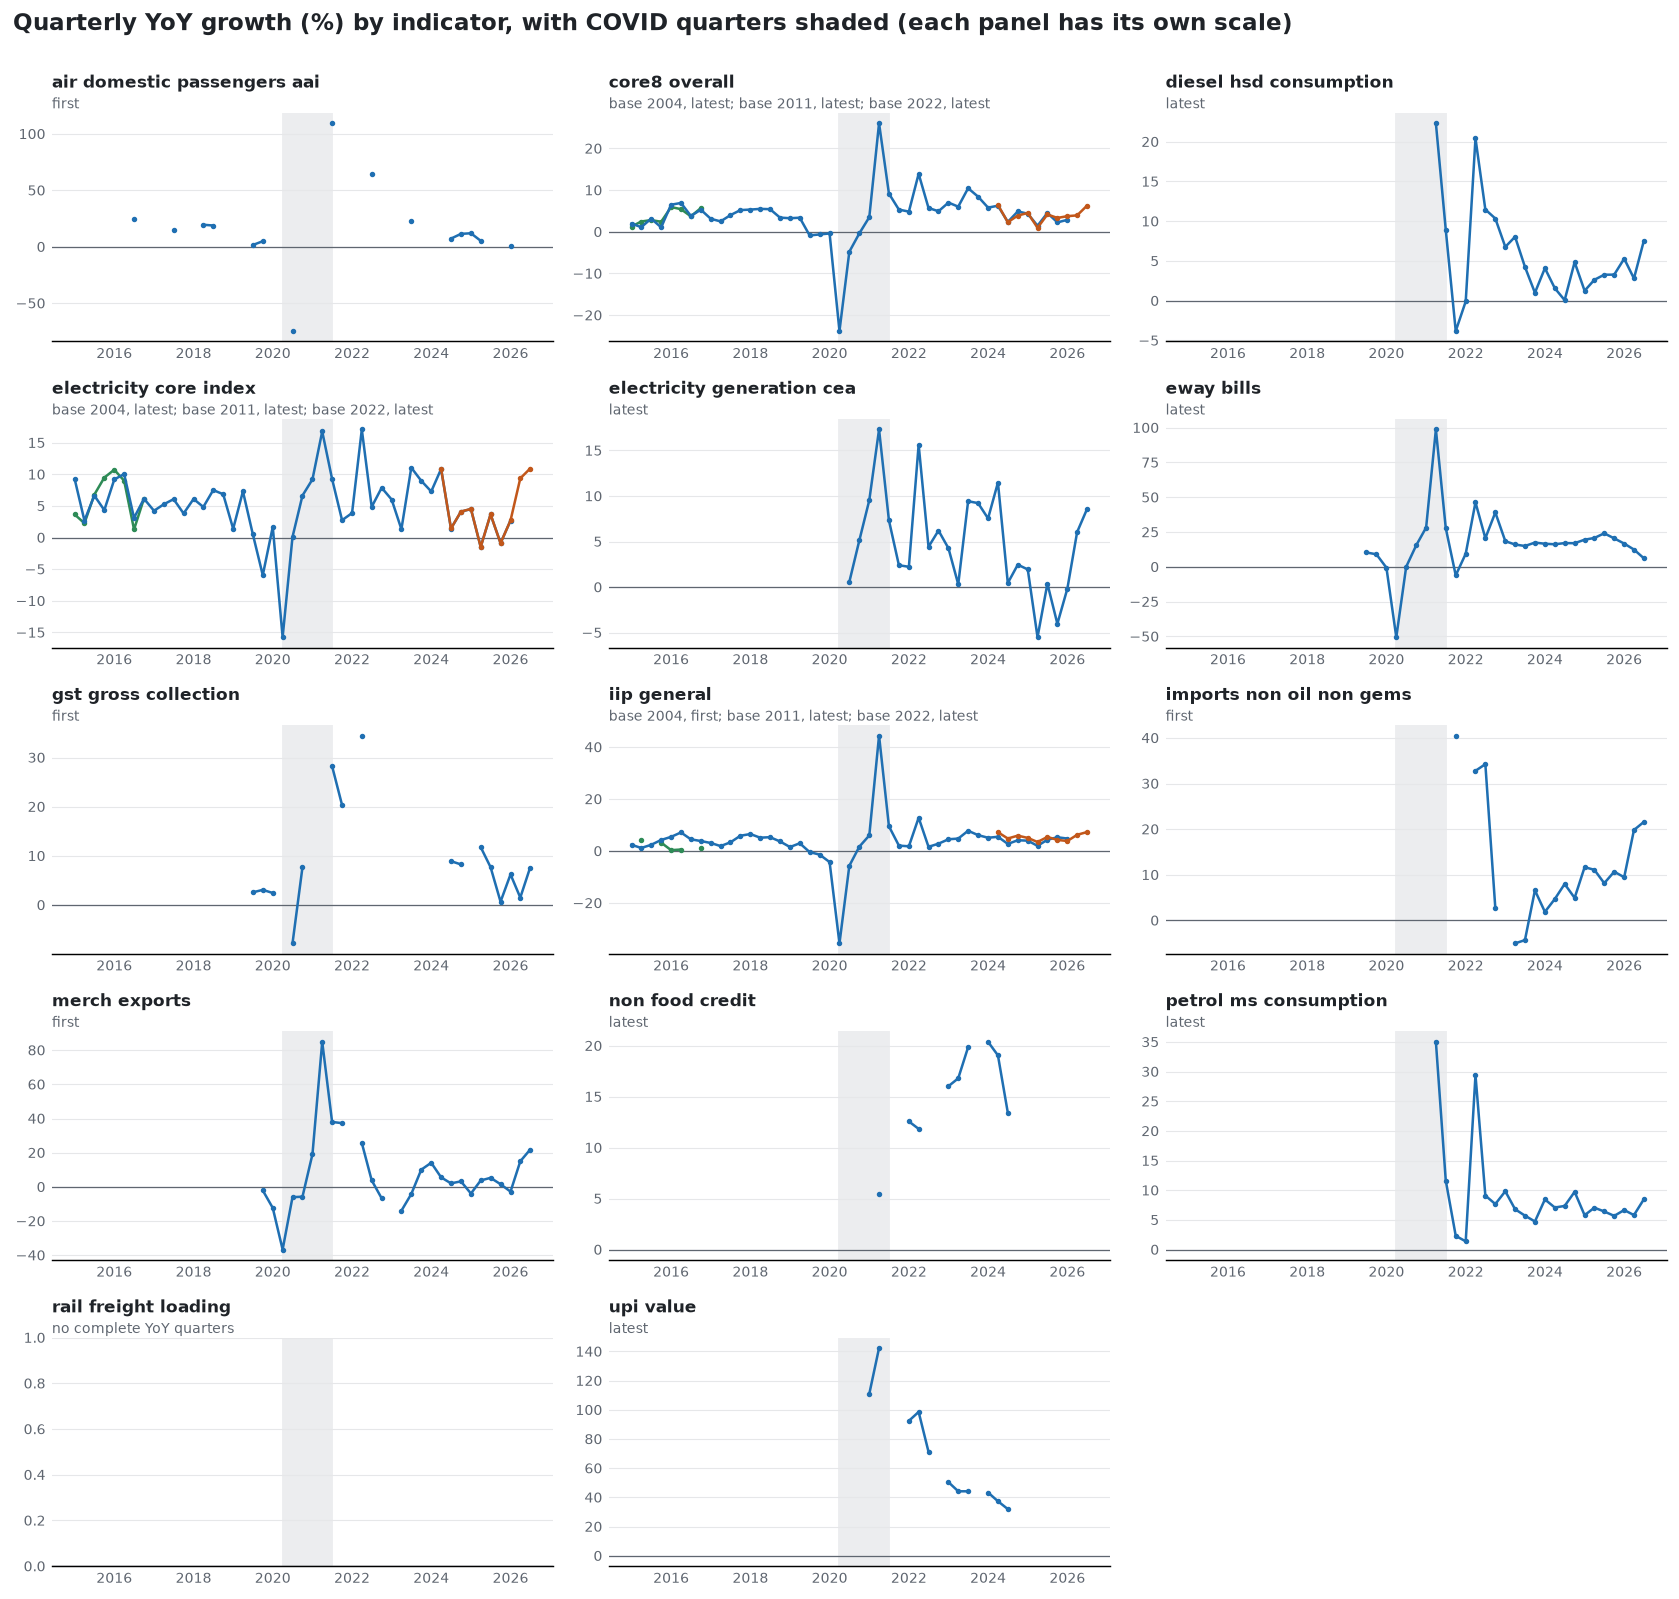

In [15]:
COLORS = {"": "#1F6FB2", "2004": "#2E8B57", "2011": "#1F6FB2", "2022": "#C2571A"}
INK, MUTED, GRID = "#1F2328", "#5F6670", "#E6E7E9"
quarterly["family"] = quarterly["indicator"].str.replace(r"_base\d{4}$", "", regex=True)
quarterly["base"] = quarterly["indicator"].str.extract(r"_base(\d{4})$")[0].fillna("")
families = sorted(quarterly["family"].unique())
cols = 3; rows_n = int(np.ceil(len(families) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(13, 2.5 * rows_n), dpi=130, sharex=True)
for ax, family in zip(axes.flat, families):
    ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2021-07-01"), color="#ECEDEF", zorder=0)
    ax.axhline(0, color=MUTED, lw=0.7)
    part = quarterly[(quarterly["family"] == family) & quarterly["yoy_pct"].notna()]
    labels = []
    for (base, vintage), g in part.groupby(["base", "vintage"]):
        # Prefer the latest vintage per base; show first prints only where there is no latest series.
        if vintage == "first" and ((part["base"] == base) & (part["vintage"] == "latest")).any():
            continue
        x = pd.PeriodIndex(g["quarter"], freq="Q").to_timestamp()
        full = pd.Series(g["yoy_pct"].values, index=x).reindex(pd.date_range(x.min(), x.max(), freq="QS"))
        ax.plot(full.index, full.values, color=COLORS[base], lw=1.4, marker="o", ms=2)
        labels.append((f"base {base}, " if base else "") + vintage)
    ax.set_title(family.replace("_", " "), loc="left", fontsize=9.5, color=INK, fontweight="bold", pad=14)
    ax.text(0, 1.02, "; ".join(labels) or "no complete YoY quarters", transform=ax.transAxes, fontsize=7.5, color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0, labelsize=7.5, labelbottom=True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
for ax in axes.flat[len(families):]:
    ax.axis("off")
fig.suptitle("Quarterly YoY growth (%) by indicator, with COVID quarters shaded (each panel has its own scale)", x=0.01, ha="left", fontsize=12.5, color=INK, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(REPORTS / "indicators_quarterly_yoy.png", bbox_inches="tight", facecolor="white")
plt.show()

## Data gaps

The coverage table above has the counts. This cell explains them. **Only the core-industry, IIP and e-way series come close to full history.**

### Sources and look-ahead risk

| Indicator | Source | Vintage | Look-ahead risk |
|---|---|---|---|
| IIP | MoSPI press notes (first), MoSPI API (latest) | First to Sep 2025 | Low to Sep 2025. **High after that: the 2022-23 base has revised data only** |
| Core 8 | OEA press releases (first), OEA XLSX (latest) | First and latest | Low |
| Diesel, petrol | PPAC | **Latest only** | **High** |
| Electricity (MU) | CEA via NPP: tentative = first, actual = latest | First and latest | Low. No release dates |
| Electricity (core sub-index) | OEA XLSX | **Latest only** | **High**, and it overlaps with core 8 |
| Rail freight | PIB releases | First only | Low |
| Domestic air | **AAI, not DGCA** | First only | Low |
| Exports, imports | PIB releases | First only | Low |
| Non-food credit, UPI | RBI Bulletin via Wayback | Earliest bulletin found | **Medium: may not be the true first print** |
| GST | PIB releases, GST portal XLSX | First | Low. Apr 2024 onward XLSX values have no release date, and may be slightly revised |
| E-way bills | GST portal XLSX | **Latest only** | **High** |

### Missing history

- **Diesel, petrol:** nothing before Apr 2020. PPAC's data call returns nothing for earlier years. Older Wayback copies of PPAC reports exist but weren't parsed.
- **Rail freight:** sparse, with no complete quarter on both sides of a YoY. Most months have no parsable PIB release.
- **Exports, imports:** nothing before 2018 and Oct 2020 respectively, and scattered months after. PIB's listing starts in 2017.
- **Non-food credit, UPI:** only bulletins captured by Wayback, ending Feb 2025. RBI's live bulletin pages could fill more, but weren't crawled.
- **Domestic air:** starts Feb 2015, with scattered missing annexes.
- **GST:** Jul 2017 to Mar 2018 and scattered months later.
- **E-way bills:** starts Jul 2018, matching the official file.
- **Electricity (MU):** starts late 2017 for tentative figures and mid-2019 for actuals.
- **Core 8 first prints:** blank for 2014-03, 2015-07, 2016-05, 2016-09, 2016-12, 2017-01 to 2017-04 and 2024-12 (no extractable index in the PDF, several of them scanned images) and 2026-09.
- **IIP first prints:** scattered blanks, and none after Sep 2025.
- **Not collected:** PMI, because no free official historical source was found. NPCI returned 403, so UPI comes from the RBI Bulletin. data.gov.in wasn't used because it needs an API key.

### Base changes and series breaks

- **IIP:** 2004-05, 2011-12 and 2022-23 bases, kept separate. First prints move from 2004-05 to 2011-12 in 2017. The 2011-12 series ends Mar 2026.
- **Core 8:** the same three bases. The 2022-23 index **adds iron ore as a ninth sector, so its composition differs** as well as its base.
- **Three IIP notes state no base.** They were assigned 2011-12, like every other note from that period, and are marked `base inferred` in the provenance file.

### Definitions that differ from the request

- **Domestic air** is passengers handled at airports (AAI), not passengers carried by airlines (DGCA). The levels aren't comparable, and YoY may differ too.
- **Imports** are non-petroleum, non-gems & jewellery, as the ministry reports them. This is narrower than non-oil non-gold, because it also excludes silver and precious stones.
- **Electricity (MU)** is the CEA summary total: thermal, nuclear, hydro and Bhutan imports. It **excludes most renewables**, so it understates generation increasingly over time.
- **E-way bills** are within-state plus outgoing. Incoming bills are excluded to avoid double-counting.
- **Non-food credit** covers select banks and is a stock, so quarters use the average of the months.

### Release dates

- Dates come from several methods, listed per row in `indicators_provenance.csv`.
- **PDF creation dates** (older core notes, AAI) are a proxy for the release date, not an announced date.
- **RBI dates** are the bulletin date, which is later than the first publication elsewhere. The 50-day lag overstates how late this data is available.
- **Rows without a credible date were removed** from the first-print vintage: 22 credit and UPI rows with unreadable bulletin dates.
- **First-print YoY** compares two first prints a year apart, so it isn't always the growth rate published in the note.

### Parsing safeguards

- First prints are compared with the latest series where both exist, and none is more than 15% away.
- Credit and UPI readings that differ more than 5% from a later bulletin are dropped, since a shifted year header can place a prior-year figure in the wrong column.
- **Unresolved:** latest non-food credit still shows month-on-month jumps of 11-15% (2020-04, 2021-01, 2021-03). These are unexplained, so treat those months with caution.
- Rail, air, exports, imports and GST have no second source in this notebook, so wrong-sentence errors can't be fully ruled out there.
